# NYC Taxi Times

**Author:** Clarice Mottet  

---

## Objective

Build a model to predict the total ride duration for NYC taxis

---

## Dataset
**Source:**
- kaggle


## Table of Contents

- [1. Load Data](#1-load-data)
- [2. Data Cleaning](#2-data-cleaning)
- [3. Exploratory Data Analysis](#3-exploratory-data-analysis)
- [4. Feature Engineering](#4-feature-engineering)
- [5. Modeling](#5-modeling)
- [6. Model Evaluation](#6-model-evaluation)


## Notes

- Random seed = 42
- Train/Test split = pre-determined by datasets given
- Evaluation metric = Root Mean Squared Log Error

# 1. Load Data

In [117]:
#libraries

import pandas as pd
import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


project_root = Path.cwd().parent          # if notebook is inside notebooks/


In [61]:
#import in the datasets
#quick look over

#establish  file path

raw_path = project_root / "data" / "raw"
os.listdir(raw_path)

df_test = pd.read_csv(raw_path / "test.csv", dtype = str)
df_train = pd.read_csv(raw_path / "train.csv", dtype = str)
df_sample = pd.read_csv(raw_path / "sample_submission.csv", dtype = str)

* Column Check:
train dataset has the columns "dropoff_datetime" and "trip_duration" which test does not

In [62]:
#perform columns check

# print(df_test.columns)
# print(df_train.columns)

list_test_col = list(df_test.columns)
list_train_col = list(df_train.columns)

list_all_col = list_test_col + list_train_col
list_all_col = list(set(list_all_col))
print(list_all_col)

list_test_doesnt = [x for x in list_all_col if x not in list_test_col]
print(list_test_doesnt)

list_train_doesnt = [x for x in list_all_col if x not in list_train_col]
# print(list_train_doesnt)

#so train has the resulting columns for me to be able to compare and train to, theres dropoff_datetime and trip duration



['id', 'pickup_latitude', 'vendor_id', 'passenger_count', 'dropoff_latitude', 'trip_duration', 'pickup_longitude', 'store_and_fwd_flag', 'pickup_datetime', 'dropoff_datetime', 'dropoff_longitude']
['trip_duration', 'dropoff_datetime']


# 2. Data Cleaning

* dtype
* nulls
* duplicates

* Data Type check:

In [63]:
# print(df_train.head())
# print(df_train.columns)

#need to identify dtypes
for col in df_train.columns:
    df_train[col] = df_train[col].str.strip()

#numeric columns
list_col_num = ['vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
                'trip_duration']
list_col_date = ['pickup_datetime', 'dropoff_datetime']


In [46]:
# df_test.head()

In [47]:
# df_train.columns

* convert train and test to numeric

In [64]:
df_ = df_train.copy()

list_convert_num = [x for x in list_col_num if x in df_.columns]
df_[list_convert_num] = df_[list_convert_num].apply(pd.to_numeric)
df_train = df_.copy()

In [65]:
df_t = df_test.copy()

list_convert_num = [x for x in list_col_num if x in df_t.columns]
df_t[list_convert_num] = df_t[list_convert_num].apply(pd.to_numeric)
df_test = df_t.copy()

In [48]:
# df_test.columns

In [49]:
# df_test.dtypes

* convert train and test to datetime

In [66]:
df_ = df_train.copy()

list_convert_date = [x for x in list_col_date if x in df_.columns]
df_[list_convert_date] = df_[list_convert_date].apply(pd.to_datetime)
df_train = df_.copy()

In [67]:
df_train.dtypes

id                            object
vendor_id                      int64
pickup_datetime       datetime64[ns]
dropoff_datetime      datetime64[ns]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag            object
trip_duration                  int64
dtype: object

In [68]:
df_ = df_test.copy()

list_convert_date = [x for x in list_col_date if x in df_.columns]
df_[list_convert_date] = df_[list_convert_date].apply(pd.to_datetime)


In [69]:
df_.dtypes

id                            object
vendor_id                      int64
pickup_datetime       datetime64[ns]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag            object
dtype: object

* there are no nulls

In [70]:
df_train.isnull().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [18]:
df_train.isna().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [71]:
null_counts = df_train.isna().sum()
null_counts = null_counts[null_counts > 0]
print(null_counts)

Series([], dtype: int64)


In [72]:
null_counts = df_test.isna().sum()
null_counts = null_counts[null_counts > 0]
print(null_counts)

Series([], dtype: int64)


In [73]:
df_train.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
       'trip_duration'],
      dtype='object')

In [74]:
#target variables
var_target = ['dropoff_datetime','trip_duration']

# df_test.columns

* check to make sure trip duration is calculated properly, it is 

In [75]:
df_view = df_train.copy()
df_view['dur_calc'] = (df_view['dropoff_datetime'] - df_view['pickup_datetime']).dt.total_seconds().astype(int)

df_view.head()

df_view['check_dur'] = (df_view['trip_duration'] - df_view['dur_calc']).abs()
df_view_ = df_view[df_view['check_dur']!=0]
# df_view_.head()
df_test.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'],
      dtype='object')

* there are no duplicates by the ID variabe in both train and test

* there are dupliactes by all other fields (1 in test, 7 in train)

In [76]:
#check for duplicates

df_view = df_test.copy()
df_view.drop_duplicates(subset = ['pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'], inplace = True)



In [77]:
df_view = df_train.copy()
df_view.drop_duplicates(subset = ['pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'], inplace = True)



* check for invalid values

In [78]:
df_train.describe()

,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1458644,1458644,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,2016-04-01 10:10:24.940037120,2016-04-01 10:26:24.432310528,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
min,1.000000e+00,2016-01-01 00:00:17,2016-01-01 00:03:31,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,2016-02-17 16:46:04.249999872,2016-02-17 17:05:32.500000,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,2016-04-01 17:19:40,2016-04-01 17:35:12,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2016-05-15 03:56:08.750000128,2016-05-15 04:10:51.750000128,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,2016-06-30 23:59:39,2016-07-01 23:02:03,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06
std,4.987772e-01,NaN,NaN,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03


# 3. Exploratory Data Analysis

* variable exploration
* distribution

## Train
* passenger_count - no issues
* pickup_datetime:
    - only jan 2016 - july 2016
    - by date: uniform
    - by time of day: fewer in early morning, some local peaks
    - by day of week: pretty uniform
* passenger_counts:
    - approx 2/3 are 1 passenger only
    - next most as 2 passengers and then 3-6 are about the same frequency
* longitude and latitude:
    - determined how many clusters are needed
    - there are approx 6k instances where the pickup point is the same as the dropoff point
    

In [85]:
df_train.head(5)

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
540693,id1177569,1,2016-04-14 21:30:01,2016-04-14 21:39:16,1,-73.971519,40.757771,-73.949677,40.784554,N,555
1305240,id3204914,1,2016-01-10 00:48:26,2016-01-10 01:01:19,2,-73.984703,40.755211,-73.983131,40.730537,N,773
1112776,id2370883,1,2016-02-01 19:18:59,2016-02-01 19:51:20,2,-73.948685,40.789043,-73.855705,40.839668,N,1941
605493,id1948022,1,2016-04-15 10:04:13,2016-04-15 10:17:01,1,-73.993736,40.741833,-73.988434,40.733974,N,768
605491,id1308247,1,2016-03-30 06:39:44,2016-03-30 06:45:37,1,-73.989815,40.734398,-73.975189,40.741436,N,353


In [125]:
df_train['store_and_fwd_flag'].describe()

count     1458644
unique          2
top             N
freq      1450599
Name: store_and_fwd_flag, dtype: object

<Axes: >

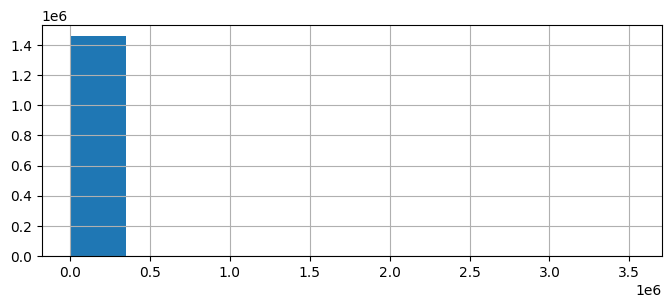

In [124]:
#histogram check

var_ = 'trip_duration'

df_train.sort_values(by = [var_], inplace = True)
df_train[var_].hist(figsize=(8,3))

In [ ]:
var_ = ''

day_counts = df_train[var_].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(day_counts.index, day_counts.values)

plt.xticks(
    ticks=range(len(day_counts))
)

plt.xlabel(var_)
plt.ylabel("freq")
plt.title("Distribution")
plt.show()

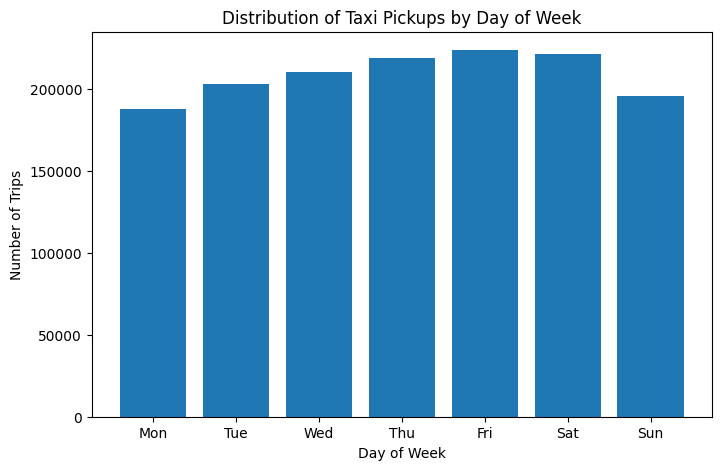

In [111]:


df_train["day_of_week"] = df_train["pickup_datetime"].dt.dayofweek

day_counts = df_train["day_of_week"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(day_counts.index, day_counts.values)

plt.xticks(
    ticks=range(7),
    labels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

plt.xlabel("Day of Week")
plt.ylabel("Number of Trips")
plt.title("Distribution of Taxi Pickups by Day of Week")
plt.show()

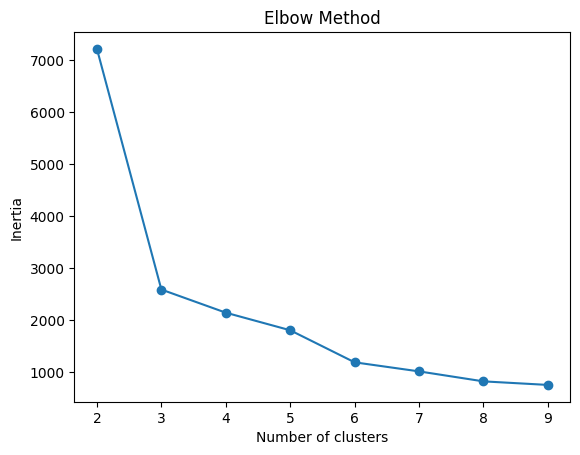

In [122]:

X = df_train[["pickup_latitude", "pickup_longitude"]]

inertia = []

for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.plot(range(2, 10), inertia, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

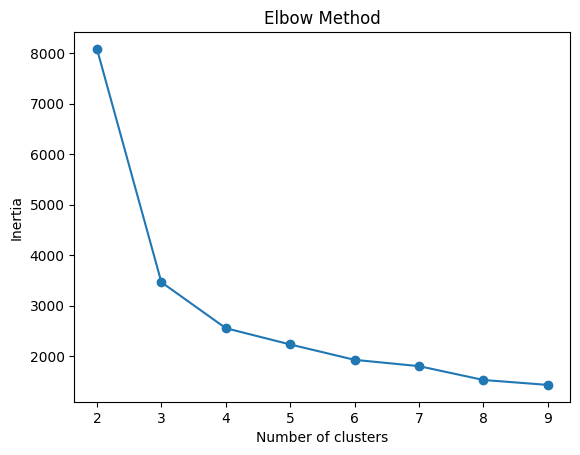

In [121]:

X = df_train[["dropoff_latitude", "dropoff_longitude"]]

inertia = []

for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.plot(range(2, 10), inertia, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [126]:


# Earth's radius in kilometers
R = 6371.0

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


# North/South component
lat_distance = haversine(
    df_train["pickup_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["pickup_longitude"]
)

# East/West component
lon_distance = haversine(
    df_train["dropoff_latitude"],
    df_train["pickup_longitude"],
    df_train["dropoff_latitude"],
    df_train["dropoff_longitude"]
)

# Manhattan distance (km)
df_train["manhattan_distance"] = lat_distance + lon_distance

In [141]:
df_train['manhattan_distance'].describe()

count    1.458644e+06
mean     4.446650e+00
std      5.659821e+00
min      0.000000e+00
25%      1.570939e+00
50%      2.688802e+00
75%      4.998980e+00
max      1.336846e+03
Name: manhattan_distance, dtype: float64

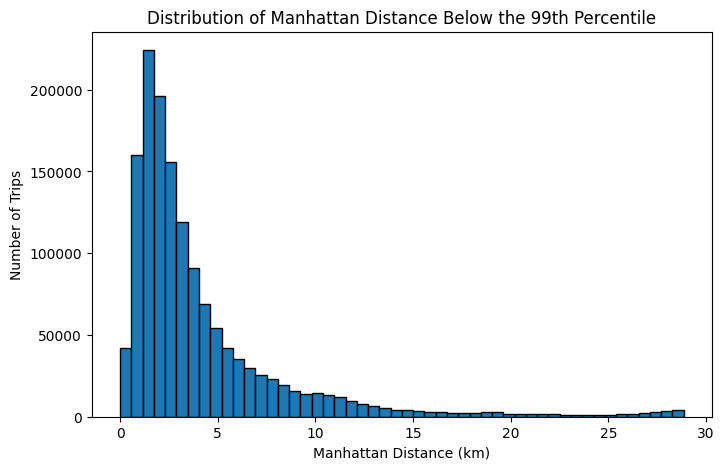

In [142]:
import matplotlib.pyplot as plt

upper_limit = df_train["manhattan_distance"].quantile(0.99)

plt.figure(figsize=(8, 5))

plt.hist(
    df_train.loc[
        df_train["manhattan_distance"] <= upper_limit,
        "manhattan_distance"
    ],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Manhattan Distance (km)")
plt.ylabel("Number of Trips")
plt.title("Distribution of Manhattan Distance Below the 99th Percentile")

plt.show()

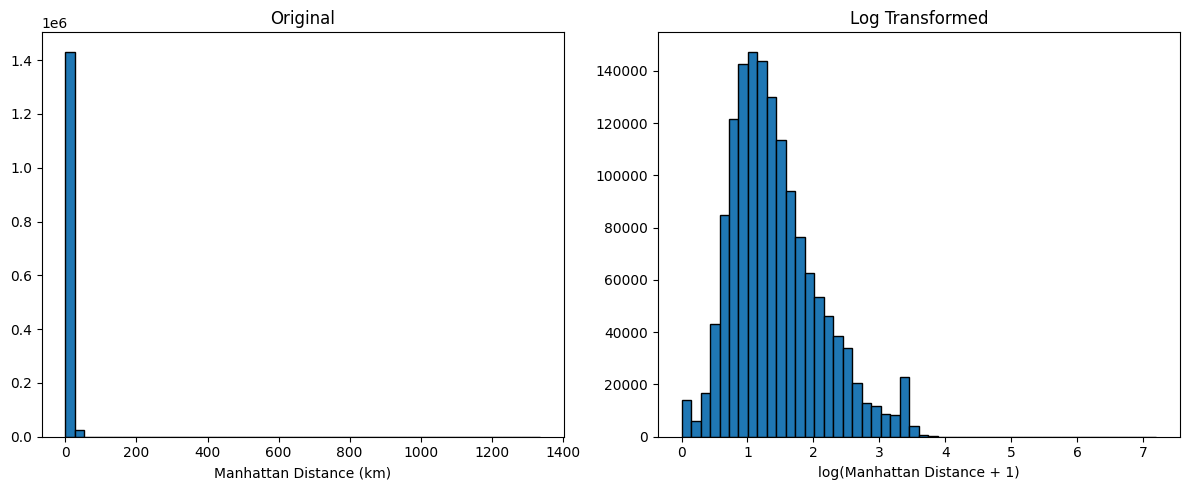

In [143]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df_train["manhattan_distance"], bins=50, edgecolor="black")
plt.title("Original")
plt.xlabel("Manhattan Distance (km)")

plt.subplot(1, 2, 2)
plt.hist(np.log1p(df_train["manhattan_distance"]), bins=50, edgecolor="black")
plt.title("Log Transformed")
plt.xlabel("log(Manhattan Distance + 1)")

plt.tight_layout()
plt.show()

<Axes: >

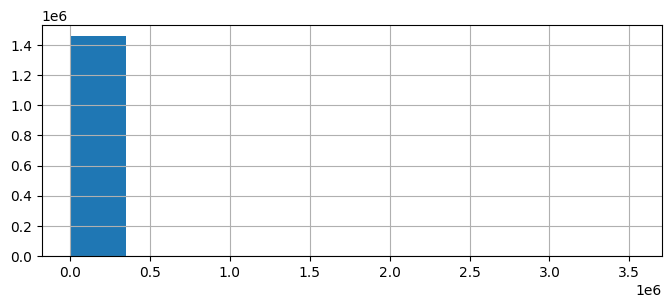

In [144]:

var_ = 'trip_duration'

df_train.sort_values(by = [var_], inplace = True)
df_train[var_].hist(figsize=(8,3))

In [131]:
df_train.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,hour,hour_sin,hour_cos,day_of_week,manhattan_distance
1256101,id0173517,2,2016-01-28 22:24:47,2016-01-28 22:31:45,2,-73.965691,40.758678,-73.965691,40.758678,N,418,22,-0.500000,0.866025,3,0.0
221374,id1953404,2,2016-05-11 07:53:18,2016-05-11 08:03:57,1,-73.962967,40.780029,-73.962967,40.780029,N,639,7,0.965926,-0.258819,2,0.0
1037795,id0864625,2,2016-06-17 08:07:09,2016-06-17 08:14:28,5,-74.006050,40.706921,-74.006050,40.706921,N,439,8,0.866025,-0.500000,4,0.0
659783,id1089208,2,2016-05-11 21:46:29,2016-05-11 21:57:08,1,-73.954102,40.778702,-73.954102,40.778702,N,639,21,-0.707107,0.707107,2,0.0
185638,id1310365,1,2016-05-25 19:41:54,2016-05-25 19:47:05,1,-73.990883,40.751236,-73.990883,40.751236,N,311,19,-0.965926,0.258819,2,0.0


In [139]:
#what is the frequency when pickup and dropoff longitude and latitude is the same

df_view = df_train.copy()
df_view = df_view[df_view['pickup_longitude']==df_view['dropoff_longitude']]
df_view = df_view[df_view['pickup_latitude']==df_view['dropoff_latitude']]
df_view['trip_duration'].describe()

count     5897.000000
mean       535.515347
std       1952.094051
min          1.000000
25%         38.000000
50%        350.000000
75%        724.000000
max      86352.000000
Name: trip_duration, dtype: float64

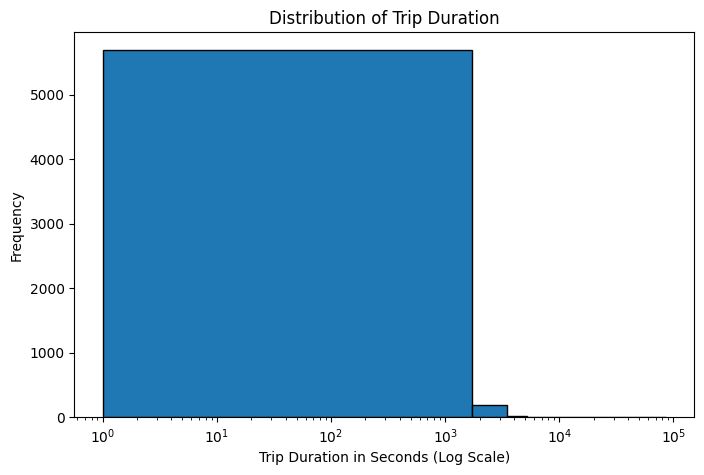

In [140]:
import matplotlib.pyplot as plt

trip_duration = df_view.loc[
    df_view["trip_duration"] > 0,
    "trip_duration"
]

plt.figure(figsize=(8, 5))

plt.hist(
    trip_duration,
    bins=50,
    edgecolor="black"
)

plt.xscale("log")
plt.xlabel("Trip Duration in Seconds (Log Scale)")
plt.ylabel("Frequency")
plt.title("Distribution of Trip Duration")

plt.show()